In [1]:
# Cell 1 — Imports and project settings
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import tensorflow as tf

# Keep the original PCU weights unchanged.
PCU_WEIGHTS = {
    'Car': 1.0,
    'Bus': 3.0,
    'Truck': 3.0,
    'Mini-Truck': 1.5,
    'CNG': 0.75,
    'Rickshaw': 0.8,
    'Motorcycle': 0.4,
    'Bicycle': 0.3,
    'Pedestrian': 0.0
}

# Keep the original congestion thresholds unchanged.
LOW_CUTOFF = 5.0
HIGH_CUTOFF = 15.80
IMG_SIZE = 224

# This order must match the order used when the ResNet50 classifier was trained.
# If flow_from_directory() was used with the same nine class folders, alphabetical
# order is normally correct.
YOLO_CLASSES = [
    'Car', 'Bus', 'Truck', 'Motorcycle', 'Bicycle',
    'Rickshaw', 'Mini-Truck', 'CNG', 'Pedestrian'
]
CNN_CLASSES = sorted(YOLO_CLASSES)
CNN_CLASS_TO_INDEX = {name: idx for idx, name in enumerate(CNN_CLASSES)}

print('TensorFlow:', tf.__version__)
print('ResNet output class order:', CNN_CLASSES)
print('PCU values:', PCU_WEIGHTS)
print(f'Thresholds: LOW < {LOW_CUTOFF}; MEDIUM {LOW_CUTOFF}–{HIGH_CUTOFF}; HIGH > {HIGH_CUTOFF}')


TensorFlow: 2.20.0
ResNet output class order: ['Bicycle', 'Bus', 'CNG', 'Car', 'Mini-Truck', 'Motorcycle', 'Pedestrian', 'Rickshaw', 'Truck']
PCU values: {'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5, 'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0}
Thresholds: LOW < 5.0; MEDIUM 5.0–15.8; HIGH > 15.8


In [2]:
# Cell 2 — Find the test dataset and model file in Kaggle Inputs
INPUT_ROOT = '/kaggle/input'
DATASET_ROOT = None

for root, dirs, files in os.walk(INPUT_ROOT):
    if os.path.basename(root).lower() == 'test':
        candidate_images = os.path.join(root, 'images')
        candidate_labels = os.path.join(root, 'labels')
        if os.path.isdir(candidate_images) and os.path.isdir(candidate_labels):
            DATASET_ROOT = os.path.dirname(root)
            break

if DATASET_ROOT is None:
    raise FileNotFoundError(
        'Could not find a dataset folder containing test/images and test/labels. '
        'Use Kaggle Add Input and make sure the dataset has this YOLO folder structure.'
    )

TEST_IMAGES_DIR = os.path.join(DATASET_ROOT, 'test', 'images')
TEST_LABELS_DIR = os.path.join(DATASET_ROOT, 'test', 'labels')

print('Dataset root:', DATASET_ROOT)
print('Test images:', TEST_IMAGES_DIR)
print('Test labels:', TEST_LABELS_DIR)

# Find full Keras models and H5 weight files. Prefer a full .keras model if present,
# because it stores the architecture as well as trained parameters.
model_candidates = []
weight_candidates = []

for root, dirs, files in os.walk(INPUT_ROOT):
    for filename in files:
        full_path = os.path.join(root, filename)
        lower = filename.lower()
        if lower.endswith('.keras'):
            model_candidates.append(full_path)
        elif lower.endswith(('.weights.h5', '.h5', '.hdf5')):
            if any(word in lower for word in ('weight', 'resnet', 'epoch', 'phase')):
                weight_candidates.append(full_path)

print('\nFull Keras model candidates:')
for path in sorted(model_candidates):
    print(path)

print('\nH5 weight candidates:')
for path in sorted(weight_candidates):
    print(path)

# Choose the best matching file automatically, but verify the printed path.
# If multiple model files are listed, manually set MODEL_PATH to the correct one.
preferred_models = [p for p in model_candidates if 'resnet' in os.path.basename(p).lower()]
MODEL_PATH = sorted(preferred_models or model_candidates)[0] if (preferred_models or model_candidates) else None

preferred_weights = [p for p in weight_candidates if 'resnet' in os.path.basename(p).lower()]
WEIGHTS_PATH = sorted(preferred_weights or weight_candidates)[0] if (preferred_weights or weight_candidates) else None

if MODEL_PATH:
    print('\nSelected full model:', MODEL_PATH)
    print('If this is not your trained ResNet50 classifier, change MODEL_PATH manually.')
elif WEIGHTS_PATH:
    print('\nSelected weights:', WEIGHTS_PATH)
    print('If this is not your trained ResNet50 classifier, change WEIGHTS_PATH manually.')
else:
    raise FileNotFoundError(
        'No .keras model or H5 weights were found under /kaggle/input. '
        'Add the trained ResNet50 model/weights using Kaggle Add Input.'
    )


Dataset root: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Test images: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Test labels: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/labels

Full Keras model candidates:

H5 weight candidates:
/kaggle/input/datasets/sharminaktermukta/resnetweight50/model.weights.h5

Selected weights: /kaggle/input/datasets/sharminaktermukta/resnetweight50/model.weights.h5
If this is not your trained ResNet50 classifier, change WEIGHTS_PATH manually.


In [3]:
# Cell 3 — Load the trained ResNet50 classifier
# Full .keras model: load its saved architecture and parameters.
# H5 weights: rebuild the architecture used by the original notebook and load weights.
if MODEL_PATH is not None:
    resnet_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print('Loaded full Keras model.')
else:
    base_model = tf.keras.applications.ResNet50(
        weights=None,
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
    x = tf.keras.layers.Dense(512, activation='relu')(x)
    output = tf.keras.layers.Dense(len(CNN_CLASSES), activation='softmax')(x)
    resnet_model = tf.keras.Model(inputs=base_model.input, outputs=output)
    resnet_model.load_weights(WEIGHTS_PATH)
    print('Loaded H5 weights into the ResNet50 architecture.')

output_units = int(resnet_model.output_shape[-1])
if output_units != len(CNN_CLASSES):
    raise ValueError(
        f'Model outputs {output_units} classes, but CNN_CLASSES contains '
        f'{len(CNN_CLASSES)} classes. Check the original training class order and model file.'
    )

print('Model loaded successfully.')
print('Model output shape:', resnet_model.output_shape)
print('IMPORTANT: Confirm that CNN_CLASSES matches the exact class order used during training.')


I0000 00:00:1792782096.727783      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792782096.731522      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Loaded H5 weights into the ResNet50 architecture.
Model loaded successfully.
Model output shape: (None, 9)
IMPORTANT: Confirm that CNN_CLASSES matches the exact class order used during training.


In [4]:
# Cell 4 — Classify annotated object crops and calculate PCU
# Note: this pipeline uses the ground-truth YOLO bounding boxes from test/labels.
# ResNet50 classifies each crop; it does not independently detect boxes in the full image.

def classify_crop(crop_bgr):
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    crop_rgb = cv2.resize(crop_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    batch = np.expand_dims(crop_rgb.astype(np.float32) / 255.0, axis=0)
    probabilities = resnet_model.predict(batch, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    return CNN_CLASSES[predicted_index], float(probabilities[predicted_index])

def congestion_level(total_pcu):
    if total_pcu < LOW_CUTOFF:
        return 'LOW'
    if total_pcu <= HIGH_CUTOFF:
        return 'MEDIUM'
    return 'HIGH'

image_paths = []
for extension in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
    image_paths.extend(glob.glob(os.path.join(TEST_IMAGES_DIR, extension)))
image_paths = sorted(set(image_paths))

if not image_paths:
    raise FileNotFoundError(f'No JPG/PNG test images found in: {TEST_IMAGES_DIR}')

print('Test images found:', len(image_paths))

results_rows = []
visual_samples = {'LOW': None, 'MEDIUM': None, 'HIGH': None}
skipped_images = 0
processed_objects = 0
images_without_valid_boxes = 0

for image_path in tqdm(image_paths, desc='ResNet50 + PCU'):
    image_name = os.path.basename(image_path)
    label_path = os.path.join(TEST_LABELS_DIR, os.path.splitext(image_name)[0] + '.txt')
    image = cv2.imread(image_path)

    if image is None or not os.path.isfile(label_path):
        skipped_images += 1
        continue

    height, width = image.shape[:2]
    class_counts = {class_name: 0 for class_name in YOLO_CLASSES}
    total_pcu = 0.0
    annotated = image.copy()
    valid_boxes_for_image = 0

    with open(label_path, 'r', encoding='utf-8') as label_file:
        label_lines = [line.strip() for line in label_file if line.strip()]

    for line in label_lines:
        parts = line.split()
        if len(parts) != 5:
            continue

        try:
            gt_id = int(parts[0])
            xc, yc, box_w, box_h = map(float, parts[1:])
        except ValueError:
            continue

        # The YOLO label ID is checked against the source dataset's class list.
        if gt_id < 0 or gt_id >= len(YOLO_CLASSES):
            continue

        x1 = max(0, int((xc - box_w / 2) * width))
        y1 = max(0, int((yc - box_h / 2) * height))
        x2 = min(width, int((xc + box_w / 2) * width))
        y2 = min(height, int((yc + box_h / 2) * height))

        if x2 <= x1 or y2 <= y1 or (x2 - x1) < 8 or (y2 - y1) < 8:
            continue

        crop = image[y1:y2, x1:x2]
        predicted_class, confidence = classify_crop(crop)
        processed_objects += 1
        valid_boxes_for_image += 1

        if predicted_class in PCU_WEIGHTS:
            class_counts[predicted_class] += 1
            total_pcu += PCU_WEIGHTS[predicted_class]

        cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 120), 2)
        cv2.putText(
            annotated, f'{predicted_class} {confidence:.2f}',
            (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX,
            0.45, (255, 255, 255), 1, cv2.LINE_AA
        )

    if valid_boxes_for_image == 0:
        images_without_valid_boxes += 1

    level = congestion_level(total_pcu)
    results_rows.append({
        'image': image_name,
        'classified_object_count': int(sum(class_counts.values())),
        'pcu_score': round(float(total_pcu), 3),
        'congestion_level': level,
        **{f'pred_{class_name}': count for class_name, count in class_counts.items()}
    })

    if visual_samples[level] is None:
        level_color = (0, 180, 0) if level == 'LOW' else ((0, 165, 255) if level == 'MEDIUM' else (0, 0, 220))
        cv2.rectangle(annotated, (0, 0), (annotated.shape[1], 58), (30, 30, 30), -1)
        cv2.putText(
            annotated, f'RESNET50 + PCU: {level} | PCU={total_pcu:.2f}',
            (15, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.7, level_color, 2, cv2.LINE_AA
        )
        visual_samples[level] = annotated

print('Images with results:', len(results_rows))
print('Classified object crops:', processed_objects)
print('Images skipped (missing/unreadable image or label):', skipped_images)
print('Images with no valid boxes:', images_without_valid_boxes)


Test images found: 2368


ResNet50 + PCU:   0%|          | 0/2368 [00:00<?, ?it/s]

I0000 00:00:1792782173.945010      69 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Images with results: 2368
Classified object crops: 26688
Images skipped (missing/unreadable image or label): 0
Images with no valid boxes: 3


In [5]:
# Cell 5 — Save CSV to Kaggle Output and display the result summary
# Run Cell 1 → Cell 5 in order. This cell needs results_rows from Cell 4.
if 'results_rows' not in globals():
    raise RuntimeError('results_rows is not defined. Run Cells 1–4 from top to bottom first.')

if not results_rows:
    raise RuntimeError(
        'No test results were produced. Check that test/images and matching test/labels/*.txt exist.'
    )

os.makedirs('/kaggle/working', exist_ok=True)
df_results = pd.DataFrame(results_rows)

csv_path = '/kaggle/working/resnet50_test_pcu_results.csv'
df_results.to_csv(csv_path, index=False)

if not os.path.isfile(csv_path) or os.path.getsize(csv_path) == 0:
    raise IOError('CSV was not saved correctly.')

print('CSV saved successfully:', csv_path)
print('Rows:', len(df_results))
print('File size (bytes):', os.path.getsize(csv_path))

summary = (
    df_results.groupby('congestion_level')
    .agg(
        image_count=('image', 'count'),
        mean_pcu=('pcu_score', 'mean'),
        min_pcu=('pcu_score', 'min'),
        max_pcu=('pcu_score', 'max')
    )
    .reindex(['LOW', 'MEDIUM', 'HIGH'])
)
print('\nCongestion summary:')
display(summary.round(3).fillna(0))
print('Overall mean PCU:', round(float(df_results['pcu_score'].mean()), 3))

print('\nCSV files currently in /kaggle/working:')
for filename in sorted(os.listdir('/kaggle/working')):
    if filename.lower().endswith('.csv'):
        print(filename)
display(df_results.head(10))


CSV saved successfully: /kaggle/working/resnet50_test_pcu_results.csv
Rows: 2368
File size (bytes): 200265

Congestion summary:


,image_count,mean_pcu,min_pcu,max_pcu
congestion_level,,,,
LOW,250,3.305,0.0,4.95
MEDIUM,1368,10.232,5.0,15.80
HIGH,750,21.180,15.8,36.40


Overall mean PCU: 12.968

CSV files currently in /kaggle/working:
resnet50_test_pcu_results.csv


,image,classified_object_count,pcu_score,congestion_level,pred_Car,pred_Bus,pred_Truck,pred_Motorcycle,pred_Bicycle,pred_Rickshaw,pred_Mini-Truck,pred_CNG,pred_Pedestrian
0,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd...,10,13.75,MEDIUM,4,3,0,0,0,0,0,1,2
1,frame0_jpg.rf.47f88bfa8857bb079cdaaffe6aa6ecd2...,20,27.90,HIGH,7,5,0,1,0,5,0,2,0
2,frame0_jpg.rf.9067d8476599d820a5497e7a4933764d...,13,15.25,MEDIUM,3,2,0,0,0,5,1,1,1
3,frame0_jpg.rf.b67d0effd101dedad76f7e39e2a02eb9...,20,26.75,HIGH,7,5,0,2,0,4,0,1,1
4,frame100_jpg.rf.f5d0a13c14dfb93b6678b392575a33...,9,13.90,MEDIUM,1,3,0,0,0,3,0,2,0
5,frame101_jpg.rf.1199a87d43701d3b1db8a5a985f806...,6,9.00,MEDIUM,3,2,0,0,0,0,0,0,1
6,frame101_jpg.rf.1ad17c9daa9cc9c269a8d09e7ff998...,17,14.50,MEDIUM,1,2,0,1,0,7,0,2,4
7,frame101_jpg.rf.1f2e8106bb6e310470a2f52b2bc578...,24,26.40,HIGH,3,6,0,2,0,2,1,2,8
8,frame101_jpg.rf.82e582fc10a003180029381a156c7f...,17,26.60,HIGH,1,8,0,2,0,1,0,0,5
9,frame101_jpg.rf.cfcec2c89004baef32d683e3cb3e1b...,8,8.75,MEDIUM,3,1,0,1,0,2,0,1,0


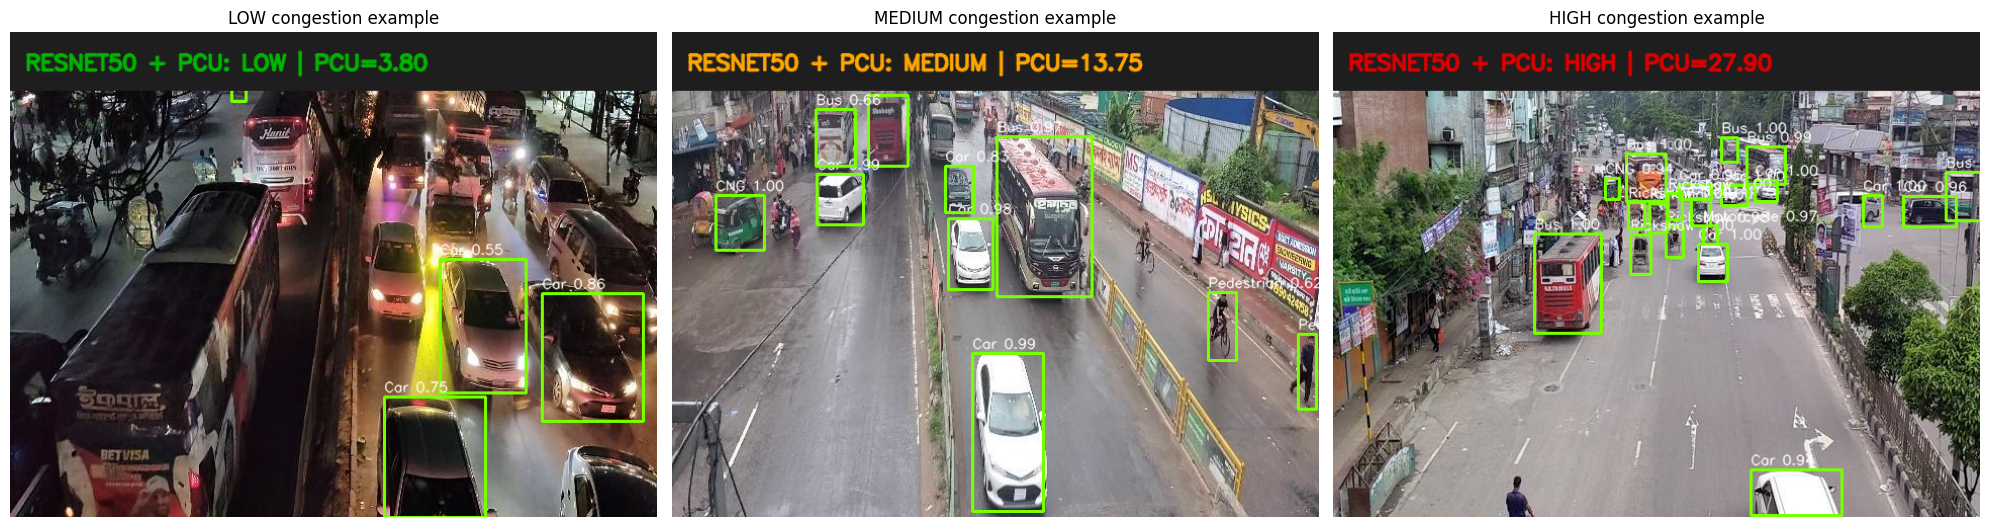

In [6]:
# Cell 6 — Display an annotated example for each congestion level
if 'visual_samples' not in globals():
    raise RuntimeError('visual_samples is not defined. Run Cells 1–4 first.')

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for axis, level in zip(axes, ['LOW', 'MEDIUM', 'HIGH']):
    sample = visual_samples.get(level)
    if sample is not None:
        axis.imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB))
        axis.set_title(f'{level} congestion example')
    else:
        axis.text(0.5, 0.5, f'No {level} example found', ha='center', va='center')
    axis.axis('off')

plt.tight_layout()
plt.show()
